In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('cleaned_HR_Employee_Attrition.csv')
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,3,4,1,6,3,3,2,2,2,2


In [32]:
df.shape

(1470, 32)

In [33]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1024.865306,2.721769,65.891156,2.729932,2.063946,2.728571,...,3.153741,2.712245,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,602.024335,1.093082,20.329428,0.711561,1.106940,1.102846,...,0.360824,1.081209,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,...,3.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,491.250000,2.000000,48.000000,2.000000,1.000000,2.000000,...,3.000000,2.000000,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1020.500000,3.000000,66.000000,3.000000,2.000000,3.000000,...,3.000000,3.000000,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1555.750000,4.000000,83.750000,3.000000,3.000000,4.000000,...,3.000000,4.000000,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,2068.000000,4.000000,100.000000,4.000000,5.000000,4.000000,...,4.000000,4.000000,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [34]:
df.describe(include='object')

,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,2
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,No
freq,1233,1043,961,606,882,326,673,1054


In [35]:
cat_cols = ['Attrition', 'BusinessTravel', 'Department', 'EducationField',
            'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
for col in cat_cols:
    df[col] = df[col].astype('category')

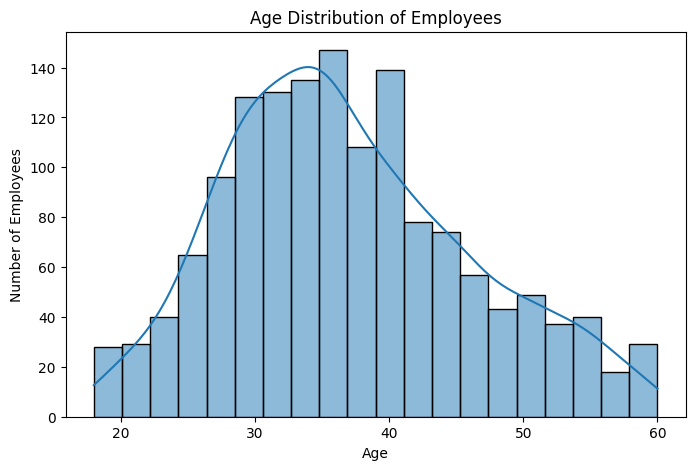

In [36]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Age'], bins=20, kde=True)
plt.title('Age Distribution of Employees')
plt.xlabel('Age')
plt.ylabel('Number of Employees')
plt.show()

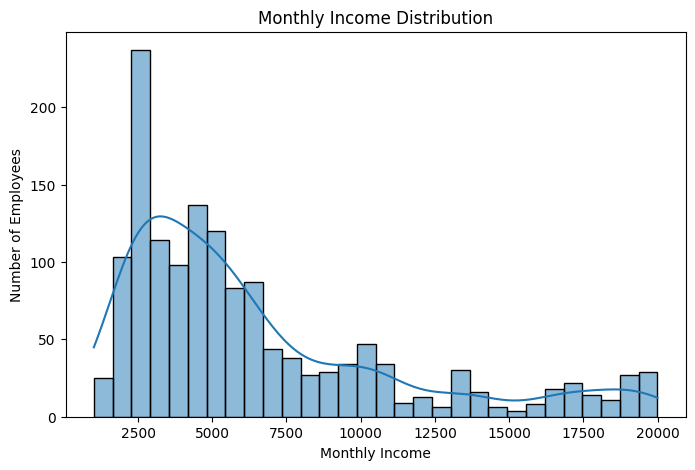

In [37]:
plt.figure(figsize=(8, 5))
sns.histplot(df['MonthlyIncome'], bins=30, kde=True)
plt.title('Monthly Income Distribution')
plt.xlabel('Monthly Income')
plt.ylabel('Number of Employees')
plt.show()

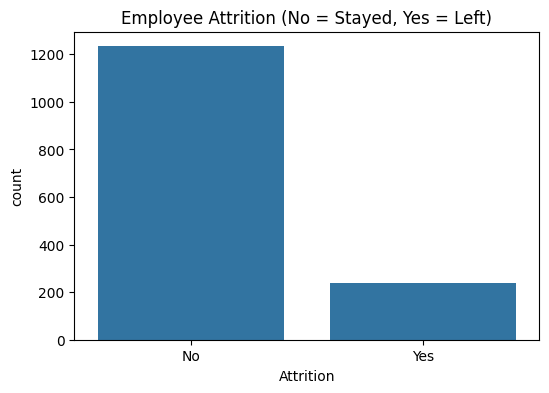

In [38]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Attrition')
plt.title('Employee Attrition (No = Stayed, Yes = Left)')
plt.show()

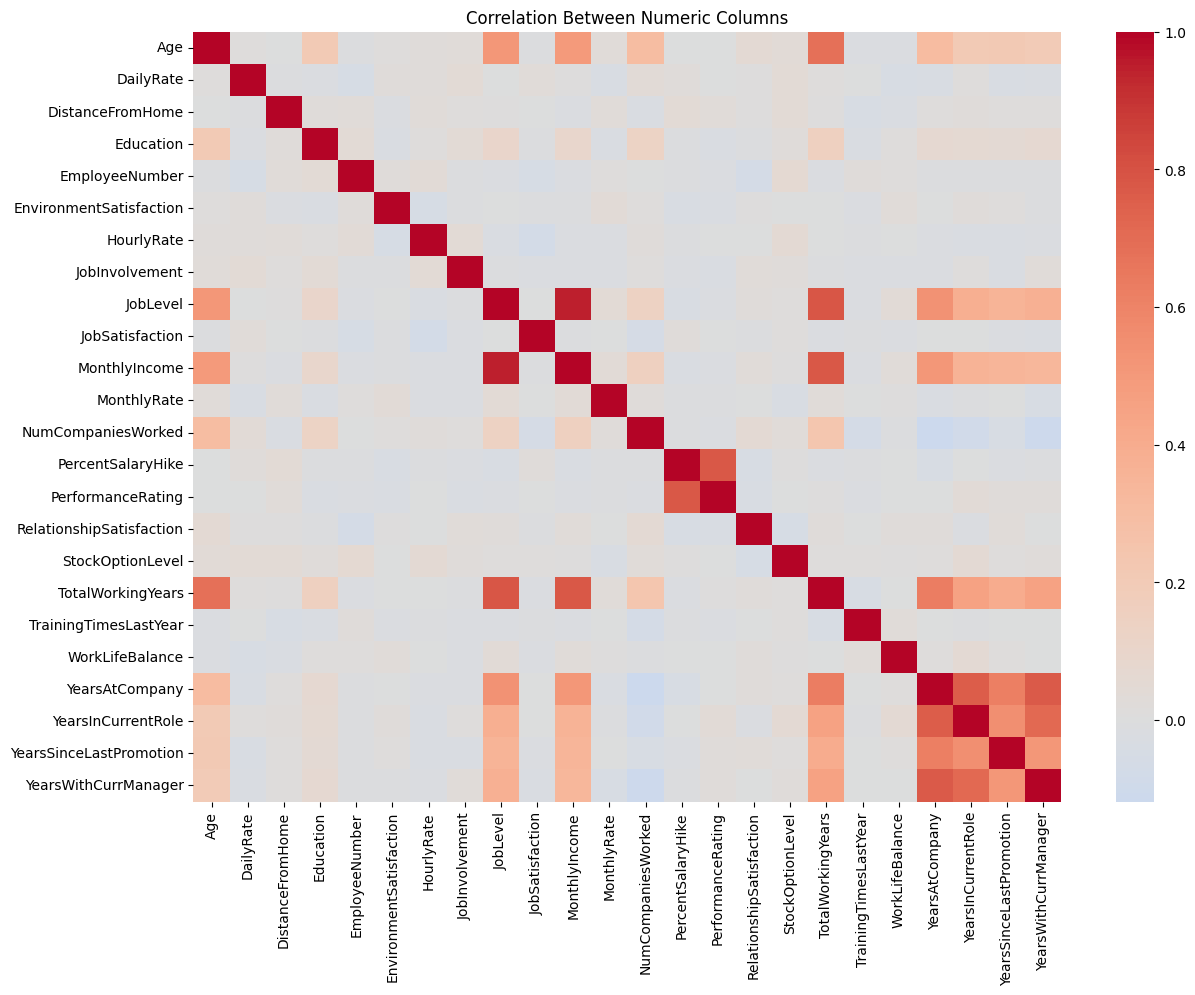

In [39]:
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(14, 10))
sns.heatmap(numeric_df.corr(), cmap='coolwarm', center=0)
plt.title('Correlation Between Numeric Columns')
plt.show()

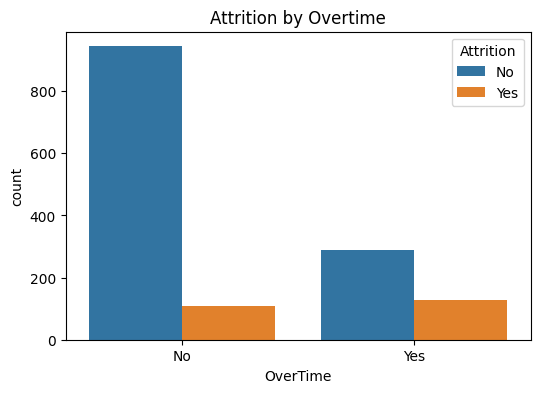

OverTime
No     10.4
Yes    30.5
Name: Attrition, dtype: float64


/tmp/ipykernel_1611/2882500633.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('OverTime')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).round(1))


In [40]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='OverTime', hue='Attrition')
plt.title('Attrition by Overtime')
plt.show()

# Percentage of employees who left, for each group
print(df.groupby('OverTime')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).round(1))

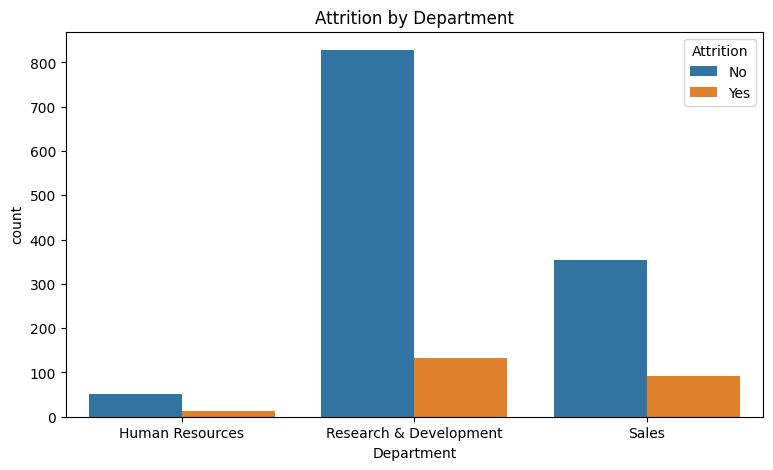

In [41]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='Department', hue='Attrition')
plt.title('Attrition by Department')
plt.show()

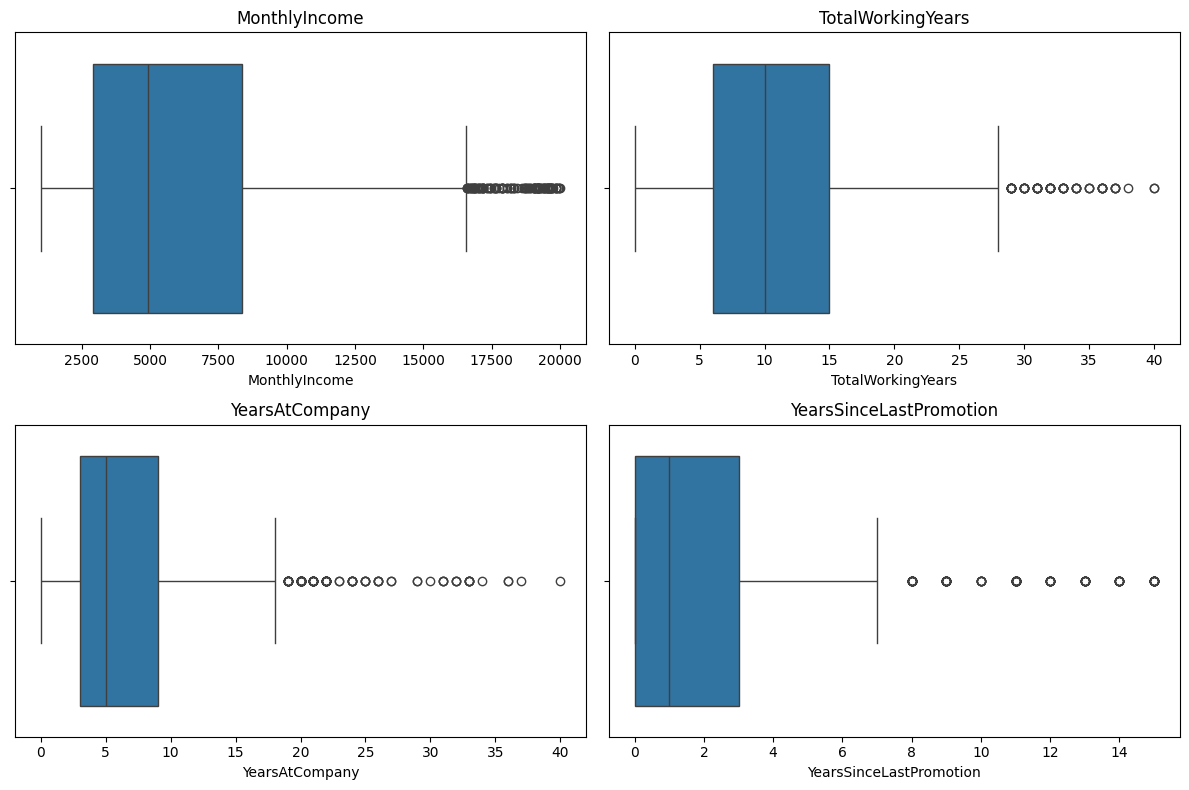

In [42]:
cols = ['MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany', 'YearsSinceLastPromotion']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [43]:
for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f'{col}: {n} outliers (normal range {lower:.0f} to {upper:.0f})')

MonthlyIncome: 114 outliers (normal range -5291 to 16581)
TotalWorkingYears: 63 outliers (normal range -8 to 28)
YearsAtCompany: 104 outliers (normal range -6 to 18)
YearsSinceLastPromotion: 107 outliers (normal range -4 to 8)


In [44]:
print('Overall attrition rate:', round((df['Attrition'] == 'Yes').mean() * 100, 1), '%')


Overall attrition rate: 16.1 %


In [45]:
print(df.groupby('JobRole')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).round(1).sort_values(ascending=False))

JobRole
Sales Representative         39.8
Laboratory Technician        23.9
Human Resources              23.1
Sales Executive              17.5
Research Scientist           16.1
Healthcare Representative     6.9
Manufacturing Director        6.9
Manager                       4.9
Research Director             2.5
Name: Attrition, dtype: float64


/tmp/ipykernel_1611/3990853676.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('JobRole')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).round(1).sort_values(ascending=False))


In [46]:
print(df.groupby('Attrition')['MonthlyIncome'].mean().round(0))

Attrition
No     6833.0
Yes    4787.0
Name: MonthlyIncome, dtype: float64


/tmp/ipykernel_1611/3682860667.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('Attrition')['MonthlyIncome'].mean().round(0))


In [47]:
print(df.groupby('JobLevel')['MonthlyIncome'].mean().round(0))


JobLevel
1     2787.0
2     5502.0
3     9817.0
4    15504.0
5    19192.0
Name: MonthlyIncome, dtype: float64


In [48]:
print(df.groupby('JobSatisfaction')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).round(1))

JobSatisfaction
1    22.8
2    16.4
3    16.5
4    11.3
Name: Attrition, dtype: float64


In [49]:
print(df.groupby('Attrition')['YearsSinceLastPromotion'].mean().round(2))

Attrition
No     2.23
Yes    1.95
Name: YearsSinceLastPromotion, dtype: float64


/tmp/ipykernel_1611/3922847291.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('Attrition')['YearsSinceLastPromotion'].mean().round(2))


In [50]:
print(df.groupby('OverTime')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).round(1))

q1, q3 = df['MonthlyIncome'].quantile([0.25, 0.75])
iqr = q3 - q1
print('MonthlyIncome outliers:', ((df['MonthlyIncome'] < q1 - 1.5*iqr) | (df['MonthlyIncome'] > q3 + 1.5*iqr)).sum())

print(df[['MonthlyIncome', 'JobLevel', 'TotalWorkingYears']].corr().round(2))

OverTime
No     10.4
Yes    30.5
Name: Attrition, dtype: float64
MonthlyIncome outliers: 114
                   MonthlyIncome  JobLevel  TotalWorkingYears
MonthlyIncome               1.00      0.95               0.77
JobLevel                    0.95      1.00               0.78
TotalWorkingYears           0.77      0.78               1.00


/tmp/ipykernel_1611/3025753965.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('OverTime')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).round(1))
